# NIST smoke alarms — fire or burnt toast? Cleaning + Qdrant + Neo4j

**City Brain · fire sensors.** 90 real room tests (2 kinds of fire, 4 kinds of cooking) with CO, CO2, temperature and smoke every second.
This one notebook does everything for this dataset:

1. **Load & clean** the NIST room tests
2. **Visualise** how fires and cooking differ
3. **Turn every minute of every test into a small numeric vector** (what the sensors saw in the last 60 s)
4. **Check offline** that nearest-neighbour search can tell fire from cooking (testing on groups it has never seen)
5. **Qdrant** (cloud): store the vectors, so a new sensor reading can be compared with all past ones
6. **Neo4j** (cloud): store *why* — which sensor signals each source raises and when
7. **Combine**: a new reading → Qdrant finds similar past moments → Neo4j explains them

### What goes where

| Store | Holds | Answers |
|---|---|---|
| **Qdrant** | one **7-number vector** per 60-second window (smoke level & trend, CO rise & trend, CO2 rise, ceiling temperature rise & trend) + a small payload (`state`, `source`, `smoke_level`, `co_confirmed`) | *"Which past moments look like this reading, and were they fires?"* |
| **Neo4j** | `Source`, `Test`, `Signal`, `Reading` nodes; which sensor signal each source raises, how often and how fast | *"Why? What should happen next if it really is a fire?"* |

Unlike the NYC 311 notebooks there is **no text to embed**: sensor data is numeric, so the vectors are built directly from the readings and compared with **Euclidean distance**.

### Graph model

| Node | Meaning |
|---|---|
| `Source` | what burned: *fire flaming*, *fire smouldering*, *broiled burger*, *fried burger*, *stir-fry*, *toast* |
| `IncidentType` | `fire` (shared with the other City Brain datasets): fire sources `INDICATE` it, cooking sources `MIMIC` it |
| `Test` | one lab test |
| `Signal` | `smoke`, `co`, `co2`, `ceiling_temp` with the threshold used |
| `Reading` | one 60-second window (same id as the Qdrant point) |

`(Source)-[:RAISES {share, median_s}]->(Signal)` is the key edge: e.g. *fire smouldering raises CO in 100 % of tests, toast in 0 %*.

> Some tests are kept **out** of Qdrant and Neo4j (`HOLDOUT_GROUPS`). They play the role of "new inputs the system has never seen".

## 0 · Setup

In [23]:
import os, io, json, re, sys, subprocess, zipfile, warnings
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from matplotlib.colors import LinearSegmentedColormap
from IPython.display import display

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)

try:
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
print("Running in Colab:", IN_COLAB)

Running in Colab: True


In [24]:
import uuid

# ---- switches ----------------------------------------------------------------
RUN_QDRANT      = True   # section 5: upload the vectors to your Qdrant Cloud cluster
RUN_NEO4J       = True   # section 6: load the graph into your Neo4j (Aura) instance
RUN_COMBINE     = True   # section 7: query Qdrant, explain with Neo4j (needs both uploads done)
RECREATE        = False   # True = delete the Qdrant collection first (destroys points already in it)
CLEAR_GRAPH     = False   # True = delete the nodes this notebook created earlier in Neo4j (tag ds = DS)
INCLUDE_CONTEXT = False   # True = also store test id / second / group in the Qdrant payload

# ---- parameters ---------------------------------------------------------------
HOLDOUT_GROUPS  = (5,)    # test groups G5 stay OUT of the databases: they are the "new, unseen" inputs
WIN, STRIDE, K  = 60, 15, 15   # window length (s), step (s), neighbours per query
DS              = "nist-smoke"            # tag on every Neo4j node we create
COLLECTION      = "nist_fire_windows"     # Qdrant collection

SOURCES = {   # file-name code -> (label, class)
    "FFoam": ("fire flaming", "fire"), "SFoam": ("fire smouldering", "fire"),
    "BHB": ("broiled burger", "nuisance"), "FryHB": ("fried burger", "nuisance"),
    "SF": ("stir-fry", "nuisance"), "Toast": ("toast", "nuisance"),
}
NAME_RE = re.compile(r"^(FFoam|SFoam|BHB|FryHB|SF|Toast)G(\d+)T(\d+)$")

In [25]:
INK, INK2, SURF, GRIDC = "#0b0b0b", "#52514e", "#fcfcfb", "#e4e3df"
SEQ = LinearSegmentedColormap.from_list("seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#184f95", "#0d366b"])
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": GRIDC, "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2,
    "text.color": INK, "axes.grid": True, "grid.color": GRIDC, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "font.size": 10,
})

In [26]:
SRC_COLORS = {"fire flaming": "#2a78d6", "fire smouldering": "#eb6834", "broiled burger": "#1baf7a",
              "fried burger": "#eda100", "stir-fry": "#e87ba4", "toast": "#6250d6"}
STATE_COLORS = {"quiet": "#9a9992", "nuisance": "#2a78d6", "fire": "#eb6834"}

## 1 · Load the room tests

You need the 90 `.tsv` files of the NIST **room** tests, either

* as a **zip** (`roomdata.zip` from the NIST download, or a zip of your repo folder `data/fire/nist-smoke-alarms/room`), or
* as the loose `.tsv` files.

In Colab just run the cell and pick the zip in the upload dialog.

In [27]:
ROOM_DIR = Path("nist_room")

def find_tests():
    roots = [ROOM_DIR, Path(".")]
    return sorted({f for r in roots if r.exists() for f in r.rglob("*.tsv") if NAME_RE.match(f.stem)})

if not find_tests():
    zips = sorted(Path(".").glob("*.zip"))
    if not zips:
        if IN_COLAB:
            from google.colab import files
            print("Select the zip with the NIST room .tsv files ...")
            files.upload()
            zips = sorted(Path(".").glob("*.zip"))
        else:
            raise FileNotFoundError("Put the room .tsv files (or a zip of them) next to the notebook.")
    for z in zips:
        with zipfile.ZipFile(z) as zf:
            zf.extractall(ROOM_DIR)

files_found = find_tests()
print(f"{len(files_found)} test files found")
assert len(files_found) > 0, "no NIST room test files found"

90 test files found


## 2 · Cleaning

One row per second, starting 60 s before ignition. Things to fix:

| Issue | Treatment |
|---|---|
| column names have stray spaces, files are `latin-1` | strip names, read as `latin-1` |
| smoke column is called `Obsc (%/ft) smoothed` in some files and `Obsc (%/ft)` in others | one name: `obsc` |
| gas analysers (CO, CO2) and thermocouples only start **at ignition** (blank before) | baseline = first 10 s after ignition; smoke baseline = the 60 s before ignition |
| every sensor has its own offset | all readings are used **relative to the test's own baseline** (a rise, not an absolute level), so they would also work for another sensor |
| file name encodes the experiment (`FFoamG1T1`) | parse source, group, trial |

In [28]:
def load_test(f):
    x = pd.read_csv(f, sep="\t", encoding="latin-1")
    x.columns = [c.strip() for c in x.columns]
    x = x.rename(columns={"Counter (s)": "t", "CO (ppm vol)": "co", "CO2 (vol %)": "co2", "TC #1 (deg C)": "tc1",
                          "Obsc (%/ft) smoothed": "obsc", "Obsc (%/ft)": "obsc"})
    x = x.loc[:, ~x.columns.duplicated()][["t", "obsc", "co", "co2", "tc1"]].apply(pd.to_numeric, errors="coerce")
    return x.dropna(subset=["t"]).drop_duplicates("t").sort_values("t").reset_index(drop=True)

tests, meta = {}, []
for f in files_found:
    code_, grp, trial = NAME_RE.match(f.stem).groups()
    x = load_test(f)
    tests[f.stem] = x
    meta.append({"test": f.stem, "code": code_, "source": SOURCES[code_][0], "class": SOURCES[code_][1],
                 "group_no": int(grp), "trial": int(trial), "duration_s": int(x.t.max()), "rows": len(x),
                 "missing_co_%": round(x.co.isna().mean() * 100, 1), "missing_obsc_%": round(x.obsc.isna().mean() * 100, 1)})
meta = pd.DataFrame(meta)
print(f"{len(meta)} tests, {int(meta.rows.sum()):,} seconds of sensor data")
display(meta.groupby("source").agg(tests=("test", "size"), groups=("group_no", "nunique"), min_duration_s=("duration_s", "min"),
                                   max_duration_s=("duration_s", "max"), missing_co_pct=("missing_co_%", "mean")).round(1)
        .reindex([v[0] for v in SOURCES.values()]))

90 tests, 101,173 seconds of sensor data


,tests,groups,min_duration_s,max_duration_s,missing_co_pct
source,,,,,
fire flaming,15,5,601,842,8.0
fire smouldering,15,5,1863,2208,2.8
broiled burger,15,5,1621,1871,3.5
fried burger,15,5,783,802,7.0
stir-fry,15,5,602,986,15.0
toast,15,5,484,852,10.3


### What a fire and cooking look like

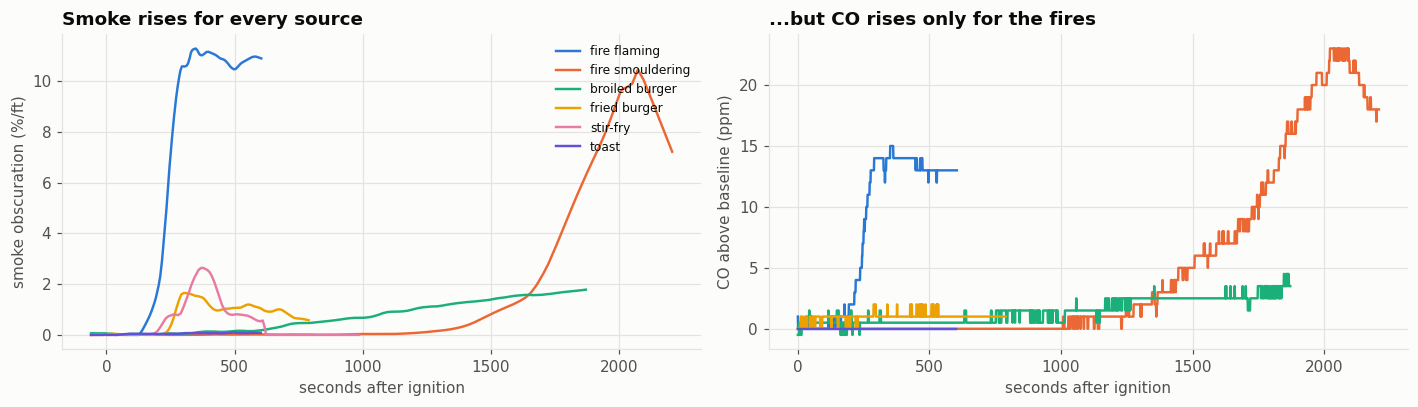

In [29]:
def baseline_of(x):
    """Per-test baseline: smoke from the 60 s before ignition, gases/temperature from the first 10 s after it."""
    pre = x.loc[x.t < 0, "obsc"].dropna()
    b = {"obsc": pre.median() if len(pre) else x.obsc.dropna().iloc[:5].median()}
    for c in ("co", "co2", "tc1"):
        b[c] = x.loc[x.t >= 0, c].dropna().iloc[:10].median()
    return b

base = {name: baseline_of(x) for name, x in tests.items()}

fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
for lab, c in SRC_COLORS.items():
    code_ = next(k for k, v in SOURCES.items() if v[0] == lab)
    name = f"{code_}G1T1"
    x = tests[name]
    ax[0].plot(x.t, x.obsc.clip(lower=0), color=c, lw=1.6, label=lab)
    ax[1].plot(x.t, x.co - base[name]["co"], color=c, lw=1.6, label=lab)
ax[0].set_title("Smoke rises for every source"); ax[0].set_ylabel("smoke obscuration (%/ft)")
ax[1].set_title("...but CO rises only for the fires"); ax[1].set_ylabel("CO above baseline (ppm)")
for a_ in ax: a_.set_xlabel("seconds after ignition")
ax[0].legend(fontsize=8, loc="upper right")
plt.tight_layout(); plt.show()

### Which sensor signal separates fire from cooking?

For each test: the second when each signal first crosses its threshold. This table becomes the `RAISES` edges of the graph.

,smoke,co,co2,ceiling_temp
source,,,,
fire flaming,"15/15, 185 s","15/15, 270 s","15/15, 218 s","15/15, 262 s"
fire smouldering,"15/15, 1340 s","15/15, 1550 s","2/15, 1220 s","1/15, 1969 s"
broiled burger,"15/15, 1230 s",0/15,0/15,"15/15, 944 s"
fried burger,"15/15, 272 s",0/15,0/15,0/15
stir-fry,"15/15, 291 s",0/15,0/15,0/15
toast,0/15,0/15,0/15,0/15


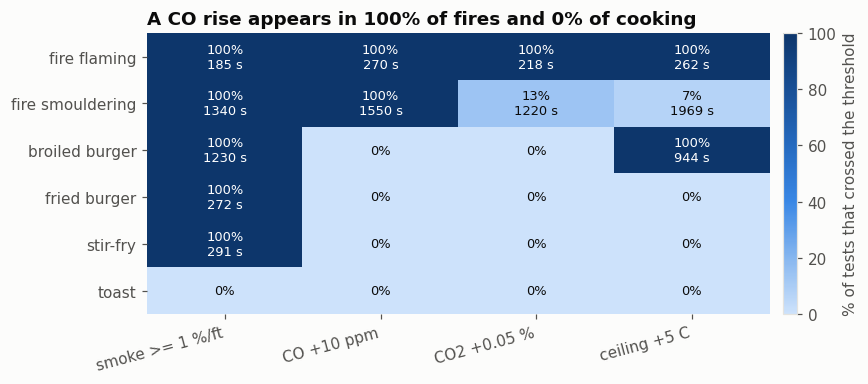

In [30]:
SIGNALS = {   # name: (column, threshold, relative to baseline?, readable label, unit)
    "smoke":        ("obsc", 1.0,  False, "smoke >= 1 %/ft",     "%/ft"),
    "co":           ("co",   10,   True,  "CO +10 ppm",          "ppm"),
    "co2":          ("co2",  0.05, True,  "CO2 +0.05 %",         "%"),
    "ceiling_temp": ("tc1",  5,    True,  "ceiling +5 C",        "C"),
}

def first_hit(x, b, col, th, relative):
    if x[col].isna().all():
        return np.nan
    hit = x[(x.t >= 0) & ((x[col] - (b[col] if relative else 0)) >= th)]
    return float(hit.t.iloc[0]) if len(hit) else np.nan

hits = meta[["test", "code", "source", "class", "group_no"]].copy()
for sig, (col, th, rel, _, _) in SIGNALS.items():
    hits[sig] = [first_hit(tests[n], base[n], col, th, rel) for n in hits.test]

def cell(s):
    return f"{s.notna().sum()}/{len(s)}" + (f", {s.median():.0f} s" if s.notna().any() else "")
display(hits.groupby("source").agg({s: cell for s in SIGNALS}).reindex([v[0] for v in SOURCES.values()]))

share = hits.groupby("source")[list(SIGNALS)].agg(lambda s: s.notna().mean()).reindex([v[0] for v in SOURCES.values()])
med   = hits.groupby("source")[list(SIGNALS)].median().reindex(share.index)
fig, ax = plt.subplots(figsize=(8, 3.6))
im = ax.imshow(share.values * 100, cmap=SEQ, vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(share.shape[1])); ax.set_xticklabels([SIGNALS[s][3] for s in share.columns], rotation=15, ha="right")
ax.set_yticks(range(share.shape[0])); ax.set_yticklabels(share.index)
for (i, j), v in np.ndenumerate(share.values):
    t_ = med.values[i, j]
    ax.text(j, i, f"{v * 100:.0f}%" + (f"\n{t_:.0f} s" if v > 0 else ""), ha="center", va="center", fontsize=8.5, color="white" if v > 0.55 else INK)
ax.grid(False)
for s_ in ax.spines.values(): s_.set_visible(False)
ax.set_title("A CO rise appears in 100% of fires and 0% of cooking")
fig.colorbar(im, ax=ax, label="% of tests that crossed the threshold", fraction=0.04, pad=0.02)
plt.tight_layout(); plt.show()

## 3 · From readings to vectors

For every test, every `STRIDE` = 15 s, we look at the **last `WIN` = 60 s** and describe it with 7 numbers (all relative to the test's baseline):

| # | Feature | Meaning |
|---|---|---|
| 1 | `obsc` | smoke obscuration level (%/ft) |
| 2 | `obsc_slope` | is smoke rising or falling (per second) |
| 3 | `co` | CO rise above baseline (ppm) |
| 4 | `co_slope` | CO trend |
| 5 | `co2` | CO2 rise (%) |
| 6 | `tc` | ceiling temperature rise (C) |
| 7 | `tc_slope` | temperature trend |

Each number goes through a **signed log** with a fixed scale (`sign(x) * log(1 + |x| / scale)`) so a +5 ppm rise and a +500 ppm rise both matter. The scales are fixed constants, not fitted to this data, so **a reading from another sensor or room can be encoded the same way**.

Every window gets a weak label `state`: `quiet` (nothing happening: smoke < 0.1, CO < +2 ppm, temperature < +2 C) otherwise the class of the test, `fire` or `nuisance` (cooking).

In [31]:
FEATURES = ["obsc", "obsc_slope", "co", "co_slope", "co2", "tc", "tc_slope"]
SCALES   = np.array([0.5, 0.005, 5.0, 0.05, 0.02, 2.0, 0.02])

def window_features(x, t_end, b, win=WIN):
    """The 7 raw numbers describing the last `win` seconds ending at `t_end` (None if too little data)."""
    w = x[(x.t > t_end - win) & (x.t <= t_end) & (x.t >= 0)]
    if len(w) < 20:
        return None
    def fin(v): return 0.0 if pd.isna(v) else float(v)       # analyser missing in this window -> assume "no rise"
    def lvl(c): return fin(w[c].mean() - b[c])
    def slope(c):
        v = w[c].dropna()
        return fin((v.iloc[-5:].mean() - v.iloc[:5].mean()) / max(len(v) - 5, 1)) if len(v) > 10 else 0.0
    return {"obsc": max(lvl("obsc"), 0.0), "obsc_slope": slope("obsc"), "co": lvl("co"), "co_slope": slope("co"),
            "co2": lvl("co2"), "tc": lvl("tc1"), "tc_slope": slope("tc1")}

def encode(feats):
    """raw feature table/dict -> signed-log vectors (n, 7)."""
    a = np.nan_to_num(np.asarray(pd.DataFrame(feats if not isinstance(feats, dict) else [feats])[FEATURES], dtype=float))
    return np.sign(a) * np.log1p(np.abs(a) / SCALES)

def smoke_level(v):
    return "none" if v < 0.1 else "low" if v < 1 else "moderate" if v < 5 else "high"

rec = []
for name, x in tests.items():
    m = meta.loc[meta.test == name].iloc[0]
    for te in range(30, int(x.t.max()) + 1, STRIDE):
        f = window_features(x, te, base[name])
        if f:
            rec.append({"test": name, "source": m.source, "class": m["class"], "group_no": m.group_no, "trial": m.trial, "t_sec": te,
                        "duration_s": m.duration_s, **f})
W = pd.DataFrame(rec)
W["state"]       = np.where((W.obsc < 0.1) & (W.co < 2) & (W.tc < 2), "quiet", W["class"])
W["smoke_level"] = W.obsc.map(smoke_level)
W["co_confirmed"] = W.co >= 10
W["holdout"]     = W.group_no.isin(HOLDOUT_GROUPS)
X = encode(W)
print(f"{len(W):,} windows x {X.shape[1]} features | train {int((~W.holdout).sum()):,} | held out {int(W.holdout.sum()):,}")
display(pd.crosstab(W.source, W.state).reindex([v[0] for v in SOURCES.values()]))

6,262 windows x 7 features | train 4,998 | held out 1,264


state,fire,nuisance,quiet
source,,,
fire flaming,545,0,134
fire smouldering,1000,0,1048
broiled burger,0,1569,75
fried burger,0,654,113
stir-fry,0,396,218
toast,0,219,291


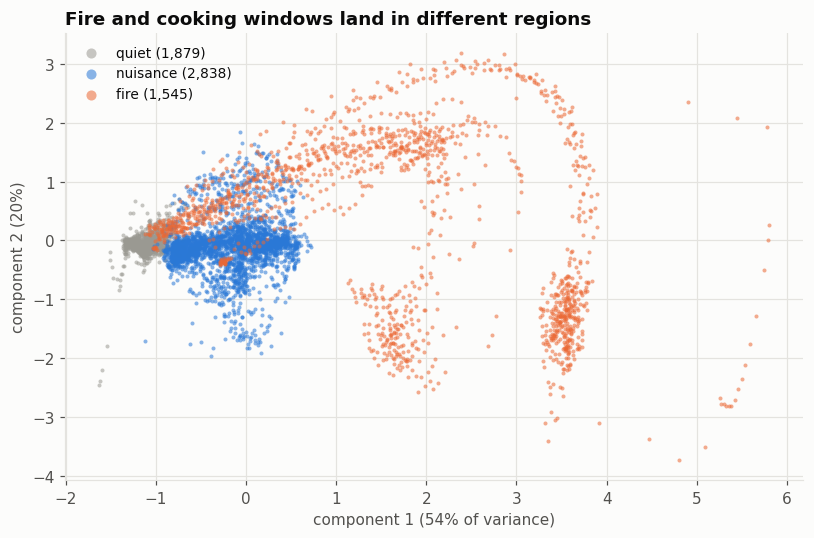

In [32]:
# 2-D picture of the 7-D space (PCA via SVD): do the states form regions?
Xc = X - X.mean(0)
U, S, Vt = np.linalg.svd(Xc, full_matrices=False)
P = Xc @ Vt[:2].T
fig, ax = plt.subplots(figsize=(7.5, 5))
for st in ["quiet", "nuisance", "fire"]:
    m = (W.state == st).to_numpy()
    ax.scatter(P[m, 0], P[m, 1], s=7, color=STATE_COLORS[st], alpha=0.55, lw=0, label=f"{st} ({m.sum():,})")
ax.set_xlabel(f"component 1 ({S[0]**2 / (S**2).sum() * 100:.0f}% of variance)"); ax.set_ylabel(f"component 2 ({S[1]**2 / (S**2).sum() * 100:.0f}%)")
ax.set_title("Fire and cooking windows land in different regions")
ax.legend(markerscale=2.5, fontsize=9)
plt.tight_layout(); plt.show()

## 4 · Does similarity search work? (offline check, no cloud needed)

For every window we ask the **15 nearest windows from other experiments** and take a majority vote.
Strict rule: when testing a window, **all tests of its own source + group are removed** from the search (leave-one-group-out), so it cannot just find its own twin trials.

This is exactly what Qdrant will do later, so it tells us what to expect.

In [33]:
STATE_ID = {"quiet": 0, "nuisance": 1, "fire": 2}
ID_STATE = {v: k for k, v in STATE_ID.items()}

def knn_predict(Xq, Xdb, ydb, k=K, gq=None, gdb=None, chunk=1000):
    """Euclidean kNN with majority vote. If gq/gdb are given, neighbours from the same group are ignored."""
    sqd = (Xdb ** 2).sum(1)
    pred, conf = np.empty(len(Xq), dtype=int), np.empty(len(Xq))
    for i in range(0, len(Xq), chunk):
        xq = Xq[i:i + chunk]
        d = np.sqrt(np.maximum((xq ** 2).sum(1)[:, None] + sqd[None, :] - 2 * xq @ Xdb.T, 0))
        if gq is not None:
            d[gq[i:i + chunk][:, None] == gdb[None, :]] = np.inf
        nn = np.argpartition(d, k, axis=1)[:, :k]
        votes = np.stack([(ydb[nn] == c).sum(1) for c in range(3)], axis=1)
        pred[i:i + chunk], conf[i:i + chunk] = votes.argmax(1), votes.max(1) / k
    return pred, conf

y   = W.state.map(STATE_ID).to_numpy()
grp = (W.source + "|G" + W.group_no.astype(str)).to_numpy()
W["pred"], W["conf"] = knn_predict(X, X, y, gq=grp, gdb=grp)
W["pred"] = W.pred.map(ID_STATE)

print(f"Window-level accuracy (leave-one-group-out): {(W.pred == W.state).mean() * 100:.1f}%\n")
display(pd.crosstab(W.state, W.pred).reindex(index=["quiet", "nuisance", "fire"], columns=["quiet", "nuisance", "fire"], fill_value=0))

amb = W[(W.obsc >= 1) & (W.co < 10)]
print(f"Hardest case - smoke present but CO still below +10 ppm: {len(amb):,} windows")
display(pd.crosstab(amb.state, amb.pred))

Window-level accuracy (leave-one-group-out): 97.2%



pred,quiet,nuisance,fire
state,,,
quiet,1822,49,8
nuisance,6,2817,15
fire,69,29,1447


Hardest case - smoke present but CO still below +10 ppm: 1,378 windows


pred,fire,nuisance
state,,
fire,311,3
nuisance,5,1059


,tests,knn_flagged,knn_median_s,smoke_median_s,co_flagged,co_median_s
source,,,,,,
fire flaming,15,15,180.0,185.0,15,270.0
fire smouldering,15,15,1140.0,1340.0,15,1550.0
broiled burger,15,0,NaN,1230.0,0,NaN
fried burger,15,0,NaN,272.0,0,NaN
stir-fry,15,2,322.0,291.0,0,NaN
toast,15,0,NaN,NaN,0,NaN


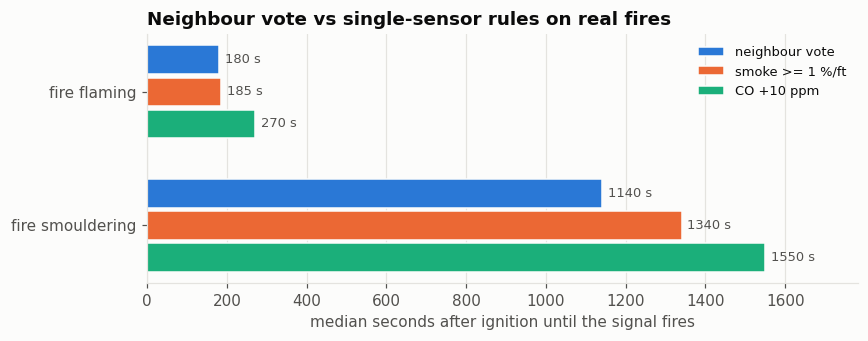

False fire flags on cooking tests: 2 of 60


In [34]:
# How early would the neighbour vote raise a fire alarm? (2 consecutive "fire" votes) vs the single-sensor rules
flag = {}
for name, g in W.sort_values("t_sec").groupby("test"):
    f = (g.pred == "fire").to_numpy(); t = g.t_sec.to_numpy()
    flag[name] = next((t[i] for i in range(1, len(g)) if f[i] and f[i - 1]), np.nan)
hits["knn_fire_flag"] = hits.test.map(flag)

summary = hits.groupby("source").agg(tests=("test", "size"),
        knn_flagged=("knn_fire_flag", lambda s: s.notna().sum()), knn_median_s=("knn_fire_flag", "median"),
        smoke_median_s=("smoke", "median"), co_flagged=("co", lambda s: s.notna().sum()), co_median_s=("co", "median"),
        ).reindex([v[0] for v in SOURCES.values()])
display(summary.round(0))

fire_src = ["fire flaming", "fire smouldering"]
bars = {"neighbour vote": "knn_median_s", "smoke >= 1 %/ft": "smoke_median_s", "CO +10 ppm": "co_median_s"}
cols = ["#2a78d6", "#eb6834", "#1baf7a"]
fig, ax = plt.subplots(figsize=(8, 3.2))
h = 0.24
for i, (lab, col) in enumerate(bars.items()):
    vals = [summary.loc[s, col] for s in fire_src]
    b = ax.barh(np.arange(2) + (i - 1) * h, vals, height=h * 0.9, color=cols[i], edgecolor=SURF, label=lab)
    for rect, v in zip(b, vals):
        ax.text(v + 15, rect.get_y() + rect.get_height() / 2, f"{v:.0f} s", va="center", fontsize=8.5, color=INK2)
ax.set_yticks(range(2)); ax.set_yticklabels(fire_src); ax.invert_yaxis()
ax.set_xlabel("median seconds after ignition until the signal fires"); ax.set_xlim(0, max(summary.loc[fire_src, list(bars.values())].max()) * 1.15)
ax.set_title("Neighbour vote vs single-sensor rules on real fires")
ax.grid(axis="y", visible=False); ax.legend(fontsize=8.5, loc="upper right")
plt.tight_layout(); plt.show()

false_flags = int(hits[hits["class"] == "nuisance"].knn_fire_flag.notna().sum())
print(f"False fire flags on cooking tests: {false_flags} of {int((hits['class'] == 'nuisance').sum())}")

> **How to read this honestly.** These are 90 lab tests of one room and one kind of material (polyurethane foam), repeated three times per setup. A neighbour vote that works here shows the *method* is sound; it does **not** prove a cheap sensor in a real flat will behave the same. Sensor offsets, noise and drift will blur the regions. The same pipeline is meant to be re-run with your own readings.

## 5 · Qdrant — store the vectors

Only **train** windows are uploaded. The held-out groups (`HOLDOUT_GROUPS`) stay out, so later they act as brand-new readings.

* vector = the 7 encoded numbers, distance = **Euclidean** (magnitude matters for sensor data)
* point id = a fixed UUID from `test + second`, the same id used for the `Reading` node in Neo4j
* payload is small: `state`, `class`, `source`, `smoke_level`, `co_confirmed`, and the 4 rounded readings. With `INCLUDE_CONTEXT = True` it also stores `test`, `t_sec`, `group_no`.

Credentials: Colab **Secrets** (key icon) `QDRANT_URL` and `QDRANT_API_KEY`, with *Notebook access* on. If missing, the cell asks (key typed hidden).

In [35]:
def secret(name, prompt, hidden=False, default=None):
    """Colab Secrets -> environment variable -> prompt. Nothing is stored in the notebook."""
    import getpass
    val = None
    if IN_COLAB:
        try:
            from google.colab import userdata
            val = userdata.get(name)
        except Exception:
            val = None
    val = val or os.environ.get(name)
    if not val and default is None:
        val = (getpass.getpass if hidden else input)(prompt + ": ")
    return (val or default).strip()

In [36]:
_qdrant = {}

def get_qdrant():
    """Connect to your Qdrant Cloud cluster once (URL + API key from Colab Secrets)."""
    if "client" not in _qdrant:
        try:
            import qdrant_client  # noqa: F401
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "qdrant-client"], check=True)
        from qdrant_client import QdrantClient
        url = secret("QDRANT_URL", "Qdrant URL (from the Qdrant Cloud dashboard)").rstrip("/")
        key = secret("QDRANT_API_KEY", "Qdrant API key", hidden=True)
        client = QdrantClient(url=url, api_key=key, timeout=60)
        try:
            client.get_collections()
        except Exception as e:
            raise RuntimeError(f"Could not reach Qdrant at {url}. Check the URL (https://..., port 6333 if needed) and the API key. Original error: {e}")
        _qdrant["client"] = client
    return _qdrant["client"]

def upload_points(collection, ids, vectors, payloads, distance="Euclid", keyword_indexes=(), recreate=False, batch=256):
    """Create the collection if needed (never deleted unless recreate=True) and upsert the points in batches."""
    from qdrant_client import models
    client = get_qdrant()
    dist = {"Euclid": models.Distance.EUCLID, "Cosine": models.Distance.COSINE}[distance]
    dim = int(vectors.shape[1])
    existing = [c.name for c in client.get_collections().collections]
    print("Collections on the cluster:", existing)
    if collection in existing and recreate:
        client.delete_collection(collection); existing.remove(collection)
    if collection not in existing:
        client.create_collection(collection, vectors_config=models.VectorParams(size=dim, distance=dist))
        print(f"Created collection '{collection}' ({dim} dims, {distance})")
    else:
        cfg = client.get_collection(collection).config.params.vectors
        if getattr(cfg, "size", dim) != dim:
            raise ValueError(f"Collection '{collection}' has {cfg.size} dims but the vectors have {dim}. Use another name or recreate=True.")
        print(f"Collection '{collection}' already exists - upserting into it")
    for field in keyword_indexes:
        client.create_payload_index(collection, field_name=field, field_schema="keyword")
    for i in range(0, len(ids), batch):
        client.upsert(collection, wait=True, points=[
            models.PointStruct(id=ids[j], vector=vectors[j].tolist(), payload=payloads[j])
            for j in range(i, min(i + batch, len(ids)))])
        if (i // batch) % 10 == 0:
            print(f"  uploaded {min(i + batch, len(ids)):,} / {len(ids):,}")
    print("points in collection:", client.count(collection, exact=True).count)

def qdrant_search(collection, vector, k=15, query_filter=None):
    """k nearest stored points: list of (id, distance, payload). With Euclid, smaller distance = more similar."""
    client = get_qdrant()
    res = client.query_points(collection, query=[float(v) for v in vector], limit=k, query_filter=query_filter, with_payload=True).points
    return [(str(h.id), float(h.score), h.payload) for h in res]

def qdrant_search_batch(collection, vectors, k=15, chunk=64):
    """Many queries at once -> list of lists of (id, distance, payload)."""
    from qdrant_client import models
    client = get_qdrant()
    out = []
    for i in range(0, len(vectors), chunk):
        reqs = [models.QueryRequest(query=[float(v) for v in vec], limit=k, with_payload=True) for vec in vectors[i:i + chunk]]
        for r in client.query_batch_points(collection, requests=reqs):
            out.append([(str(h.id), float(h.score), h.payload) for h in r.points])
    return out

In [40]:
try:
    import qdrant_client
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "qdrant-client"], check=True)

train = W[~W.holdout].reset_index(drop=True)
Xtr   = encode(train)
train["point_id"] = [str(uuid.uuid5(uuid.NAMESPACE_URL, f"nist-smoke|{t}|{s}")) for t, s in zip(train.test, train.t_sec)]
assert train.point_id.is_unique

def payload_of(r):
    p = {"state": r.state, "class": r.class_, "source": r.source, "smoke_level": r.smoke_level,
         "co_confirmed": bool(r.co_confirmed), "obsc": round(float(r.obsc), 3), "co_rise": round(float(r.co), 2),
         "co2_rise": round(float(r.co2), 4), "tc_rise": round(float(r.tc), 2), "dataset": "nist-smoke"}
    if INCLUDE_CONTEXT:
        p.update({"test": r.test, "t_sec": int(r.t_sec), "group_no": int(r.group_no)})
    return p

_tr = train.rename(columns={"class": "class_"})
payloads = [payload_of(r) for r in _tr.itertuples()]
print(f"{len(train):,} points ready (vector size {Xtr.shape[1]}). Example payload:\n", json.dumps(payloads[len(payloads) // 2], indent=2))

if RUN_QDRANT:
    upload_points(COLLECTION, train.point_id.tolist(), Xtr, payloads, distance="Euclid",
                  keyword_indexes=["state", "source", "class"], recreate=RECREATE)
else:
    print("\nRUN_QDRANT is False - skipping the upload.")

4,998 points ready (vector size 7). Example payload:
 {
  "state": "quiet",
  "class": "nuisance",
  "source": "stir-fry",
  "smoke_level": "none",
  "co_confirmed": false,
  "obsc": 0.0,
  "co_rise": 0.0,
  "co2_rise": -0.017,
  "tc_rise": 0.71,
  "dataset": "nist-smoke"
}
Collections on the cluster: ['nyc311_calls']
Created collection 'nist_fire_windows' (7 dims, Euclid)
  uploaded 256 / 4,998
  uploaded 2,816 / 4,998
points in collection: 4998


## 6 · Neo4j — store the explanation

Add in Colab **Secrets**: `NEO4J_URI` (`neo4j+s://xxxx.databases.neo4j.io`), `NEO4J_USERNAME`, `NEO4J_PASSWORD`, optional `NEO4J_DATABASE`.
(An idle Aura Free instance may be **paused** - resume it in the Aura console first.)

* every node created here is tagged `ds = "nist-smoke"`; `CLEAR_GRAPH = True` deletes **only** those
* everything uses `MERGE`: running it twice duplicates nothing
* `IncidentType {name: 'fire'}` is a **shared** node: the other City Brain datasets attach to the same one

In [41]:
_driver, NEO4J_DB = None, "neo4j"

def get_driver():
    """Create the Neo4j driver once and reuse it."""
    global _driver, NEO4J_DB
    if _driver is None:
        try:
            import neo4j  # noqa: F401
        except ImportError:
            subprocess.run([sys.executable, "-m", "pip", "install", "-q", "neo4j"], check=True)
        from neo4j import GraphDatabase
        uri  = secret("NEO4J_URI", "Neo4j URI (neo4j+s://...)")
        user = secret("NEO4J_USERNAME", "Neo4j username", default="neo4j")
        pwd  = secret("NEO4J_PASSWORD", "Neo4j password", hidden=True)
        NEO4J_DB = secret("NEO4J_DATABASE", "", default="neo4j")
        drv = GraphDatabase.driver(uri, auth=(user, pwd))
        try:
            drv.verify_connectivity()
        except Exception as e:
            raise RuntimeError(f"Could not connect to Neo4j at {uri}. Is the Aura instance running (not paused)? "
                               f"Check URI / user / password. Original error: {e}")
        _driver = drv
    return _driver

def q(query, **params):
    """Run a read query, return a list of plain dicts."""
    with get_driver().session(database=NEO4J_DB) as s:
        return [r.data() for r in s.run(query, **params)]

def q_raw(query, **params):
    """Run a query and keep the driver objects (nodes / paths) - used for drawing."""
    with get_driver().session(database=NEO4J_DB) as s:
        return list(s.run(query, **params))

def rows(frame):
    """DataFrame -> list of plain dicts (NaN -> None, numpy -> python): safe to send to Neo4j."""
    return json.loads(frame.to_json(orient="records"))

def clear_graph():
    """Delete only the nodes THIS notebook created (tagged ds = DS). Shared IncidentType nodes are never touched."""
    total = 0
    with get_driver().session(database=NEO4J_DB) as s:
        while True:
            n = s.run("MATCH (n {ds: $ds}) WITH n LIMIT 5000 DETACH DELETE n RETURN count(*) AS n", ds=DS).single()["n"]
            total += n
            if n == 0:
                break
    print(f"deleted {total:,} nodes tagged ds = '{DS}'")

def load(query, data, size=1000, **extra):
    """Send `data` to Neo4j in batches; `query` must start with UNWIND $rows AS r."""
    with get_driver().session(database=NEO4J_DB) as s:
        for i in range(0, len(data), size):
            s.run(query, rows=data[i:i + size], ds=DS, **extra).consume()

def load_rel(rel, a_label, a_key, b_label, b_key, data, size=2000, props=()):
    sets = (" SET " + ", ".join(f"x.{p} = r.{p}" for p in props)) if props else ""
    load(f"UNWIND $rows AS r MATCH (a:{a_label} {{{a_key}: r.a}}), (b:{b_label} {{{b_key}: r.b}}) MERGE (a)-[x:{rel}]->(b){sets}", data, size)

def make_constraints(pairs):
    with get_driver().session(database=NEO4J_DB) as s:
        for label, key in pairs:
            s.run(f"CREATE CONSTRAINT {label.lower()}_{key} IF NOT EXISTS FOR (n:{label}) REQUIRE n.{key} IS UNIQUE").consume()

In [42]:
# ---------------- graph tables (train data only) ----------------
tr_tests = meta[~meta.group_no.isin(HOLDOUT_GROUPS)]
hits_tr  = hits[~hits.group_no.isin(HOLDOUT_GROUPS)]

n_source = rows(pd.DataFrame([{"code": c, "label": l, "class": k} for c, (l, k) in SOURCES.items()]))
n_signal = rows(pd.DataFrame([{"name": n, "label": v[3], "threshold": v[1], "unit": v[4], "relative": v[2]} for n, v in SIGNALS.items()]))
n_test   = rows(tr_tests[["test", "source", "group_no", "trial", "duration_s"]].rename(columns={"test": "id"}))
n_reading = rows(train.rename(columns={"point_id": "id"})[["id", "t_sec", "state", "smoke_level", "obsc", "co", "co2", "tc", "co_confirmed"]]
                 .rename(columns={"co": "co_rise", "co2": "co2_rise", "tc": "tc_rise"}).round(4))

r_oftest  = rows(pd.DataFrame({"a": tr_tests.test, "b": tr_tests.source}))
r_fromtest = rows(pd.DataFrame({"a": train.point_id, "b": train.test}))
srt = train.sort_values(["test", "t_sec"])
nxt = srt.assign(b=srt.groupby("test").point_id.shift(-1)).dropna(subset=["b"])
r_next    = rows(pd.DataFrame({"a": nxt.point_id, "b": nxt.b}))
r_raised  = [{"a": r.test, "b": sig, "t_sec": float(getattr(r, sig))} for r in hits_tr.itertuples() for sig in SIGNALS if pd.notna(getattr(r, sig))]
raises = []
for lab, g in hits_tr.groupby("source"):
    for sig in SIGNALS:
        h = int(g[sig].notna().sum())
        raises.append({"a": lab, "b": sig, "tests": int(len(g)), "hits": h, "share": round(h / len(g), 3),
                       "median_s": float(g[sig].median()) if h else None})
r_raises  = rows(pd.DataFrame(raises))
r_indicates = [{"a": l, "b": "fire"} for c, (l, k) in SOURCES.items() if k == "fire"]
r_mimics    = [{"a": l, "b": "fire"} for c, (l, k) in SOURCES.items() if k == "nuisance"]

plan = pd.DataFrame([
    ("nodes", "Source", len(n_source)), ("nodes", "Signal", len(n_signal)), ("nodes", "Test", len(n_test)),
    ("nodes", "Reading", len(n_reading)), ("nodes", "IncidentType (shared)", 1),
    ("rels", "OF_SOURCE", len(r_oftest)), ("rels", "FROM_TEST", len(r_fromtest)), ("rels", "NEXT", len(r_next)),
    ("rels", "RAISED", len(r_raised)), ("rels", "RAISES", len(r_raises)),
    ("rels", "INDICATES", len(r_indicates)), ("rels", "MIMICS", len(r_mimics)),
], columns=["kind", "name", "to_load"])
print(f"{plan[plan.kind == 'nodes'].to_load.sum():,} nodes and {plan[plan.kind == 'rels'].to_load.sum():,} relationships")
plan

5,081 nodes and 10,149 relationships


,kind,name,to_load
0,nodes,Source,6
1,nodes,Signal,4
2,nodes,Test,72
3,nodes,Reading,4998
4,nodes,IncidentType (shared),1
5,rels,OF_SOURCE,72
6,rels,FROM_TEST,4998
7,rels,NEXT,4926
8,rels,RAISED,123
9,rels,RAISES,24


In [44]:
Q_SOURCE = "UNWIND $rows AS r MERGE (s:Source {label: r.label}) SET s.code = r.code, s.class = r.class, s.ds = $ds"
Q_SIGNAL = "UNWIND $rows AS r MERGE (g:Signal {name: r.name}) SET g.label = r.label, g.threshold = r.threshold, g.unit = r.unit, g.relative = r.relative, g.ds = $ds"
Q_TEST   = "UNWIND $rows AS r MERGE (t:Test {id: r.id}) SET t.group_no = r.group_no, t.trial = r.trial, t.duration_s = r.duration_s, t.ds = $ds"
Q_READING = ("UNWIND $rows AS r MERGE (x:Reading {id: r.id}) SET x.t_sec = r.t_sec, x.state = r.state, x.smoke_level = r.smoke_level, "
             "x.obsc = r.obsc, x.co_rise = r.co_rise, x.co2_rise = r.co2_rise, x.tc_rise = r.tc_rise, x.co_confirmed = r.co_confirmed, x.ds = $ds")

def load_graph():
    make_constraints([("Source", "label"), ("Signal", "name"), ("Test", "id"), ("Reading", "id"), ("IncidentType", "name")])
    if CLEAR_GRAPH:
        clear_graph()
    load(Q_SOURCE, n_source); load(Q_SIGNAL, n_signal); load(Q_TEST, n_test); load(Q_READING, n_reading)
    with get_driver().session(database=NEO4J_DB) as s:
        s.run("MERGE (i:IncidentType {name: 'fire'})").consume()      # shared node, no ds tag on purpose
    load_rel("OF_SOURCE", "Test", "id", "Source", "label", r_oftest)
    load_rel("FROM_TEST", "Reading", "id", "Test", "id", r_fromtest)
    load_rel("NEXT", "Reading", "id", "Reading", "id", r_next)
    load_rel("RAISED", "Test", "id", "Signal", "name", r_raised, props=("t_sec",))
    load_rel("RAISES", "Source", "label", "Signal", "name", r_raises, props=("tests", "hits", "share", "median_s"))
    load_rel("INDICATES", "Source", "label", "IncidentType", "name", r_indicates)
    load_rel("MIMICS", "Source", "label", "IncidentType", "name", r_mimics)

if RUN_NEO4J:
    get_driver()
    print("Connected to Neo4j. Database:", NEO4J_DB)
    load_graph()
    got_nodes = {r["label"]: r["n"] for r in q("MATCH (n) WHERE n.ds = $ds OR n:IncidentType RETURN labels(n)[0] AS label, count(*) AS n", ds=DS)}
    got_rels  = {r["rel"]: r["n"] for r in q("MATCH (a)-[r]->(b) WHERE a.ds = $ds RETURN type(r) AS rel, count(*) AS n", ds=DS)}
    check = plan.copy()
    check["in_neo4j"] = [got_nodes.get(n.split(" ")[0], 0) if k == "nodes" else got_rels.get(n, 0) for k, n in zip(check.kind, check.name)]
    check["ok"] = check.in_neo4j >= check.to_load
    display(check)
    assert check.ok.all(), "Some counts are lower than expected - see the table above"
    print("Graph loaded and verified.")
else:
    print("RUN_NEO4J is False - skipping the connection and the load.")

Connected to Neo4j. Database: <your-aura-db>


,kind,name,to_load,in_neo4j,ok
0,nodes,Source,6,6,True
1,nodes,Signal,4,4,True
2,nodes,Test,72,72,True
3,nodes,Reading,4998,4998,True
4,nodes,IncidentType (shared),1,3,True
5,rels,OF_SOURCE,72,72,True
6,rels,FROM_TEST,4998,4998,True
7,rels,NEXT,4926,4926,True
8,rels,RAISED,123,123,True
9,rels,RAISES,24,24,True


Graph loaded and verified.


### Questions for the graph

In [45]:
if RUN_NEO4J:
    print("Which signal does each source raise? (share of tests, median second)")
    t = pd.DataFrame(q("""
        MATCH (s:Source)-[r:RAISES]->(g:Signal)
        RETURN s.label AS source, s.class AS class, g.name AS signal, r.hits AS hits, r.tests AS tests, r.share AS share, r.median_s AS median_s"""))
    display(t.pivot(index="source", columns="signal", values="share").reindex([v[0] for v in SOURCES.values()]))

    print("Cooking sources that MIMIC a fire, and the one signal that still gives them away:")
    display(pd.DataFrame(q("""
        MATCH (s:Source)-[:MIMICS]->(:IncidentType {name: 'fire'})
        MATCH (s)-[r:RAISES]->(g:Signal {name: 'co'})
        RETURN s.label AS cooking_source, r.hits AS tests_with_CO_rise, r.tests AS tests""")))

    print("Fastest vs slowest fire: when does each signal fire?")
    display(pd.DataFrame(q("""
        MATCH (s:Source)-[:INDICATES]->(:IncidentType {name: 'fire'})
        MATCH (s)-[r:RAISES]->(g:Signal) WHERE r.hits > 0
        RETURN s.label AS fire_source, g.name AS signal, r.median_s AS median_seconds ORDER BY fire_source, median_seconds""")))
else:
    print("RUN_NEO4J is False.")

Which signal does each source raise? (share of tests, median second)


signal,ceiling_temp,co,co2,smoke
source,,,,
fire flaming,1.000,1.0,1.000,1.0
fire smouldering,0.083,1.0,0.167,1.0
broiled burger,1.000,0.0,0.000,1.0
fried burger,0.000,0.0,0.000,1.0
stir-fry,0.000,0.0,0.000,1.0
toast,0.000,0.0,0.000,0.0


Cooking sources that MIMIC a fire, and the one signal that still gives them away:


,cooking_source,tests_with_CO_rise,tests
0,broiled burger,0,12
1,fried burger,0,12
2,stir-fry,0,12
3,toast,0,12


Fastest vs slowest fire: when does each signal fire?


,fire_source,signal,median_seconds
0,fire flaming,smoke,186.5
1,fire flaming,co2,220.0
2,fire flaming,ceiling_temp,266.5
3,fire flaming,co,274.5
4,fire smouldering,co2,1220.0
5,fire smouldering,smoke,1349.5
6,fire smouldering,co,1571.5
7,fire smouldering,ceiling_temp,1969.0


### Explain one reading

`facts(reading_id)` gathers what the graph knows around a window, `describe()` turns it into a sentence, `draw_explanation()` draws it.

Window at 600 s of test SFoamG1T1 (fire smouldering, a FIRE); state quiet, smoke none. Signals already raised in this test by then: none. Across all fire smouldering tests this source raises ceiling_temp (1/12 tests, median 1969 s), co (12/12 tests, median 1572 s), co2 (2/12 tests, median 1220 s), smoke (12/12 tests, median 1350 s).


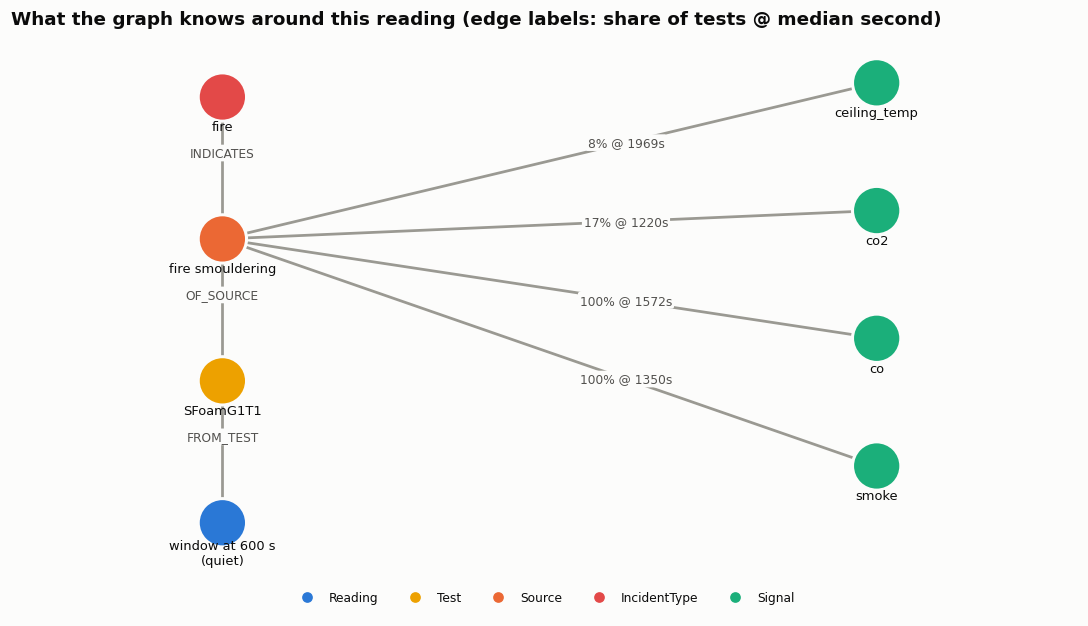

In [46]:
Q_FACTS = """
MATCH (x:Reading {id: $id})-[:FROM_TEST]->(t:Test)-[:OF_SOURCE]->(s:Source)
OPTIONAL MATCH (s)-[m:INDICATES|MIMICS]->(i:IncidentType)
RETURN x.state AS state, x.t_sec AS t_sec, x.smoke_level AS smoke_level, x.co_confirmed AS co_confirmed,
       t.id AS test, t.duration_s AS duration_s, s.label AS source, s.class AS class, type(m) AS relation, i.name AS incident_type
LIMIT 1
"""
Q_SO_FAR  = "MATCH (t:Test {id: $test})-[x:RAISED]->(g:Signal) RETURN g.name AS signal, x.t_sec AS t_sec ORDER BY t_sec"
Q_SOURCE_RAISES = """
MATCH (s:Source {label: $label})-[r:RAISES]->(g:Signal)
RETURN g.name AS signal, g.label AS signal_label, r.hits AS hits, r.tests AS tests, r.share AS share, r.median_s AS median_s ORDER BY g.name
"""

def facts(reading_id):
    rec = q(Q_FACTS, id=str(reading_id))
    if not rec:
        return None
    f = rec[0]; f["id"] = str(reading_id)
    f["signals_so_far"] = [s for s in q(Q_SO_FAR, test=f["test"]) if s["t_sec"] <= f["t_sec"]]
    f["source_raises"]  = q(Q_SOURCE_RAISES, label=f["source"])
    return f

def source_sentence(rows_):
    on  = [f"{r['signal']} ({r['hits']}/{r['tests']} tests, median {r['median_s']:.0f} s)" for r in rows_ if r["hits"]]
    off = [r["signal"] for r in rows_ if not r["hits"]]
    return ("raises " + ", ".join(on) if on else "raises no signal") + (f"; never raises {', '.join(off)}" if off else "")

def describe(f):
    if f is None:
        return "(this id is not in the graph - load the graph from the same run that built Qdrant)"
    s = (f"Window at {f['t_sec']} s of test {f['test']} ({f['source']}, a {'FIRE' if f['class'] == 'fire' else 'cooking nuisance'}); "
         f"state {f['state']}, smoke {f['smoke_level']}")
    done = f["signals_so_far"]
    s += ". Signals already raised in this test by then: " + (", ".join(f"{d['signal']} at {d['t_sec']:.0f} s" for d in done) if done else "none")
    s += f". Across all {f['source']} tests this source {source_sentence(f['source_raises'])}"
    if f.get("relation") == "MIMICS":
        s += ". It MIMICS a fire (alarms go off) but is not one"
    return s + "."

Q_PATHS = """
MATCH (x:Reading {id: $id})
OPTIONAL MATCH p1 = (x)-[:FROM_TEST]->(:Test)-[:OF_SOURCE]->(:Source)-[:INDICATES|MIMICS]->(:IncidentType)
OPTIONAL MATCH p2 = (x)-[:FROM_TEST]->(:Test)-[:OF_SOURCE]->(:Source)-[:RAISES]->(:Signal)
RETURN p1, collect(p2) AS raises
"""
NODE_COLORS = {"Reading": "#2a78d6", "Test": "#eda100", "Source": "#eb6834", "IncidentType": "#e34948", "Signal": "#1baf7a"}
LAYOUT_SLOTS = {"Reading": [(-3.5, 0)], "Test": [(-3.5, 2.0)], "Source": [(-3.5, 4.0)], "IncidentType": [(-3.5, 6.0)],
                "Signal": [(3.0, 0.8), (3.0, 2.6), (3.0, 4.4), (3.0, 6.2)]}

def _key(n): return getattr(n, "element_id", None) or n.id
def _text(n):
    lab, p = next(iter(n.labels)), dict(n.items())
    return {"Reading": f"window at {p.get('t_sec')} s\n({p.get('state')})", "Test": p.get("id"), "Source": p.get("label"),
            "IncidentType": p.get("name"), "Signal": p.get("name")}.get(lab, lab)

def draw_explanation(reading_id):
    recs = q_raw(Q_PATHS, id=str(reading_id))
    if not recs:
        print("reading not found"); return
    G, labels, kinds = nx.Graph(), {}, {}
    paths = ([recs[0]["p1"]] if recs[0]["p1"] is not None else []) + [p for p in recs[0]["raises"] if p is not None]
    for path in paths:
        for n in path.nodes:
            k = _key(n); labels[k] = _text(n); kinds[k] = next(iter(n.labels)); G.add_node(k)
        for r in path.relationships:
            lab = r.type
            if r.type == "RAISES":
                d = dict(r.items()); lab = f"{d.get('share', 0) * 100:.0f}%" + (f" @ {d['median_s']:.0f}s" if d.get("median_s") else "")
            G.add_edge(_key(r.start_node), _key(r.end_node), label=lab)
    used, pos = Counter(), {}
    for k in G.nodes:
        pos[k] = LAYOUT_SLOTS[kinds[k]][used[kinds[k]]]; used[kinds[k]] += 1
    fig, ax = plt.subplots(figsize=(10, 5.8))
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color="#9a9992", width=1.8)
    nx.draw_networkx_edge_labels(G, pos, nx.get_edge_attributes(G, "label"), ax=ax, font_size=8, font_color=INK2, rotate=False,
                                 label_pos=0.62, bbox=dict(boxstyle="round,pad=0.15", fc=SURF, ec="none"))
    nx.draw_networkx_nodes(G, pos, ax=ax, node_color=[NODE_COLORS[kinds[k]] for k in G], node_size=1000, edgecolors=SURF, linewidths=2)
    nx.draw_networkx_labels(G, {k: (x, y - 0.42) for k, (x, y) in pos.items()}, labels, ax=ax, font_size=8.5, font_color=INK)
    handles = [plt.Line2D([], [], marker="o", ls="", color=c, label=k) for k, c in NODE_COLORS.items() if k in kinds.values()]
    ax.legend(handles=handles, loc="lower center", fontsize=8, ncol=5)
    ax.set_xlim(-5.6, 5.0); ax.set_ylim(-1.3, 6.9)
    ax.set_title("What the graph knows around this reading (edge labels: share of tests @ median second)"); ax.axis("off")
    plt.tight_layout(); plt.show()

if RUN_NEO4J:
    pick = train[(train.source == "fire smouldering") & (train.t_sec >= 600)].iloc[0]
    print(describe(facts(pick.point_id)))
    draw_explanation(pick.point_id)
else:
    print("RUN_NEO4J is False.")

## 7 · Combine — Qdrant finds similar moments, Neo4j explains them

`diagnose(x, t_end)` takes **raw 1-second readings** `x` (columns `t, obsc, co, co2, tc1`) and a time `t_end`:

1. describe the last 60 s with the 7 numbers and encode them,
2. **Qdrant**: the 15 most similar past windows, then a majority vote → *quiet / cooking nuisance / fire* and how sure it is,
3. **Neo4j**: for the sources those neighbours came from, which signals they raise and how fast.

Set `RUN_COMBINE = True` (needs sections 5 and 6 done). The demo uses the **held-out groups**: readings the databases have never seen.
To try your own sensor: build a DataFrame with those 5 columns at 1 Hz (time `t` = seconds since ignition or since you started recording) and call `diagnose(your_df, t_end)`.

In [47]:
def vote(hits_):
    c = Counter(p["state"] for _, _, p in hits_)
    state, n = c.most_common(1)[0]
    return state, n / len(hits_), c

def diagnose(x, t_end, b=None, k=K, verbose=True):
    b = b or baseline_of(x)
    f = window_features(x, t_end, b)
    if f is None:
        print("not enough data in the last 60 s"); return None
    vec = encode(f)[0]
    hits_ = qdrant_search(COLLECTION, vec, k=k)
    state, share, counts = vote(hits_)
    src = Counter(p["source"] for _, _, p in hits_)
    out = {"features": f, "state": state, "confidence": share, "sources": src, "hits": hits_}
    if verbose:
        print(f"READING at {t_end} s: smoke {f['obsc']:.2f} %/ft, CO +{f['co']:.1f} ppm, CO2 +{f['co2']:.3f} %, ceiling +{f['tc']:.1f} C")
        print(f"QDRANT : {k} nearest past windows -> {dict(counts)}   verdict: {state.upper()} ({share * 100:.0f}% of neighbours)")
        print("         neighbours come from:", ", ".join(f"{s} x{n}" for s, n in src.most_common()))
        if RUN_NEO4J or _driver is not None:
            for s, n in src.most_common(2):
                print(f"NEO4J  : {s}: {source_sentence(q(Q_SOURCE_RAISES, label=s))}")
            top = hits_[0]
            print("         nearest window:", describe(facts(top[0])))
        print()
    return out

if RUN_COMBINE:
    held = meta[meta.group_no.isin(HOLDOUT_GROUPS)]
    # SFoam at 1300 s is the hard case (smouldering foam just starting to smoke, CO not up yet); at 1700 s CO has risen
    demo = [("SFoam", 1300), ("SFoam", 1700), ("FryHB", 300), ("Toast", 250), ("FFoam", 250)]
    for code_, t_end in demo:
        name = held[held.code == code_].test.iloc[0]
        print(f"=== held-out test {name} ===")
        diagnose(tests[name], t_end)
else:
    print("RUN_COMBINE is False - skipping.")

=== held-out test SFoamG5T1 ===
READING at 1300 s: smoke 0.81 %/ft, CO +2.0 ppm, CO2 +0.008 %, ceiling +0.6 C
QDRANT : 15 nearest past windows -> {'nuisance': 15}   verdict: NUISANCE (100% of neighbours)
         neighbours come from: stir-fry x9, fried burger x6
NEO4J  : stir-fry: raises smoke (12/12 tests, median 292 s); never raises ceiling_temp, co, co2
NEO4J  : fried burger: raises smoke (12/12 tests, median 273 s); never raises ceiling_temp, co, co2
         nearest window: Window at 270 s of test SFG3T3 (stir-fry, a cooking nuisance); state nuisance, smoke low. Signals already raised in this test by then: none. Across all stir-fry tests this source raises smoke (12/12 tests, median 292 s); never raises ceiling_temp, co, co2. It MIMICS a fire (alarms go off) but is not one.

=== held-out test SFoamG5T1 ===
READING at 1700 s: smoke 7.52 %/ft, CO +13.2 ppm, CO2 +0.009 %, ceiling +1.5 C
QDRANT : 15 nearest past windows -> {'fire': 15}   verdict: FIRE (100% of neighbours)
         ne

### Final check on unseen tests, straight through the cloud

Every window of the held-out tests goes through Qdrant. This compares the cloud answer with the offline numpy search (they should agree), and shows how good the system is on data it never saw.

In [48]:
if RUN_COMBINE:
    ho = W[W.holdout].reset_index(drop=True)
    Xh = encode(ho)
    res = qdrant_search_batch(COLLECTION, Xh, k=K)
    ho["cloud"] = [vote(r)[0] for r in res]
    off, _ = knn_predict(Xh, Xtr, train.state.map(STATE_ID).to_numpy())
    ho["offline"] = pd.Series(off).map(ID_STATE)
    print(f"{len(ho):,} held-out windows")
    print(f"accuracy via Qdrant  : {(ho.cloud == ho.state).mean() * 100:.1f}%")
    print(f"accuracy offline     : {(ho.offline == ho.state).mean() * 100:.1f}%")
    print(f"cloud == offline     : {(ho.cloud == ho.offline).mean() * 100:.1f}% of windows")
    display(pd.crosstab(ho.state, ho.cloud))
else:
    print("RUN_COMBINE is False - skipping.")

1,264 held-out windows
accuracy via Qdrant  : 98.7%
accuracy offline     : 98.7%
cloud == offline     : 100.0% of windows


cloud,fire,nuisance,quiet
state,,,
fire,314,5,5
nuisance,0,625,0
quiet,0,6,309


## What's next

* **Your own sensors**: the 7 features only need smoke, CO, CO2 and temperature *relative to a baseline*. Record 1 Hz readings from a cheap sensor next to a toaster and a lit foam sample (safely), run `diagnose(...)`, and see how far the lab regions move.
* **Same graph, other datasets**: the shared `IncidentType {name:'fire'}` node is where air-quality, call and fire-department data can attach later.
* **Add the commercial alarm results** from the NIST summary workbook (ionisation / photoelectric alarms that sounded on cooking) as `Alarm` nodes linked to `Source`: it shows why an alarm alone is not enough.